Project team : TEAM

Team member:
SANGEETHA P ,
RESHMA BLESSY R ,
SANJEETHA E

Business domain : Supply Chain
Illustrative client : BluePeak Distribution
Algorithms / methods Time Series, XGBoost, Prophet

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
import pandas as pd

df = pd.read_csv("/content/retail_store_inventory.csv")
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [ ]:
df.shape

(73100, 15)

In [ ]:

df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast',
       'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion',
       'Competitor Pricing', 'Seasonality'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory usage: 8.4+

In [ ]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


In [ ]:
df.isnull().sum()

,0
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Units Sold'].sum()

np.int64(9975582)

In [ ]:
df['Units Sold'].mean()

np.float64(136.46487004103966)

In [ ]:
df['Units Sold'].max()

499

In [ ]:
df['Units Sold'].min()

0

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

df['Month'] = df['Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Units Sold'].sum()

monthly_sales

,Units Sold
Month,
2022-01,419938
2022-02,391052
2022-03,426073
2022-04,407380
2022-05,414799
2022-06,415509
2022-07,426628
2022-08,424916
2022-09,411610


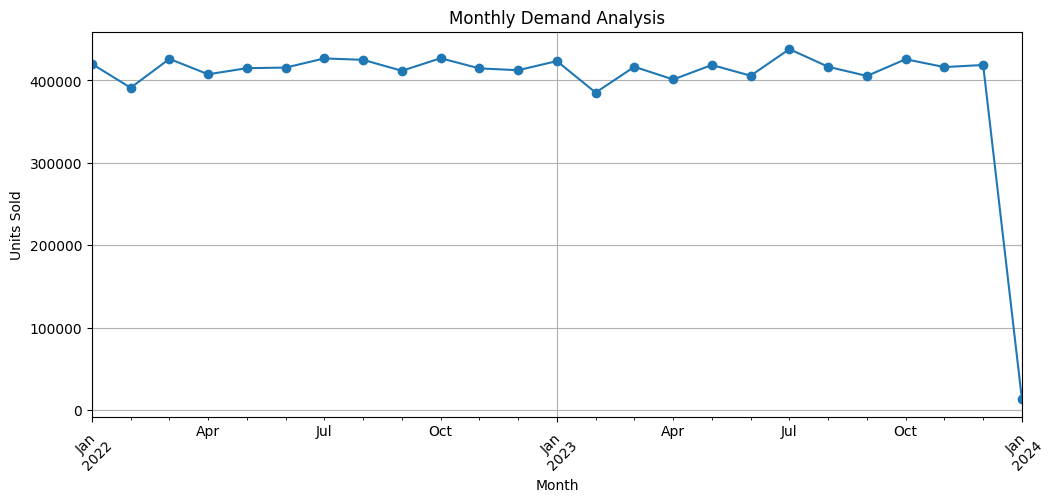

In [ ]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind='line', figsize=(12,5), marker='o')

plt.title('Monthly Demand Analysis')
plt.xlabel('Month')
plt.ylabel('Units Sold')
plt.xticks(rotation=45)
plt.grid()
plt.show()

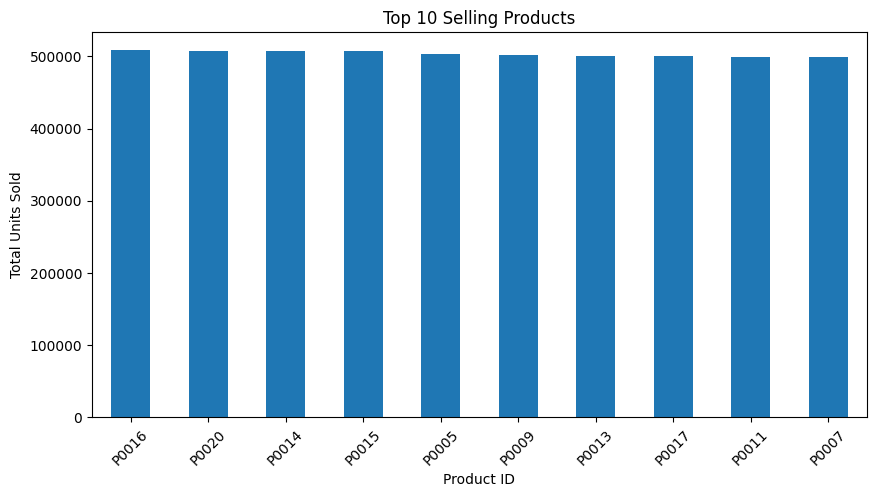

In [ ]:
top_products = df.groupby('Product ID')['Units Sold'].sum().sort_values(ascending=False).head(10)

top_products.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 Selling Products')
plt.xlabel('Product ID')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=45)
plt.show()

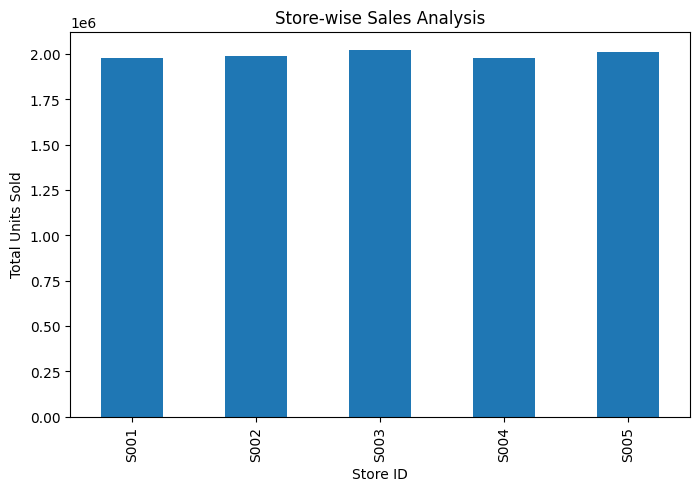

In [ ]:
store_sales = df.groupby('Store ID')['Units Sold'].sum()

store_sales.plot(kind='bar', figsize=(8,5))

plt.title('Store-wise Sales Analysis')
plt.xlabel('Store ID')
plt.ylabel('Total Units Sold')
plt.show()

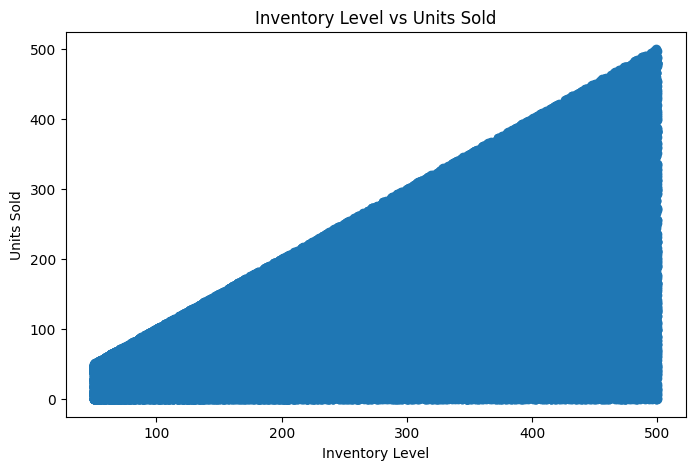

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['Inventory Level'], df['Units Sold'])

plt.title('Inventory Level vs Units Sold')
plt.xlabel('Inventory Level')
plt.ylabel('Units Sold')
plt.show()

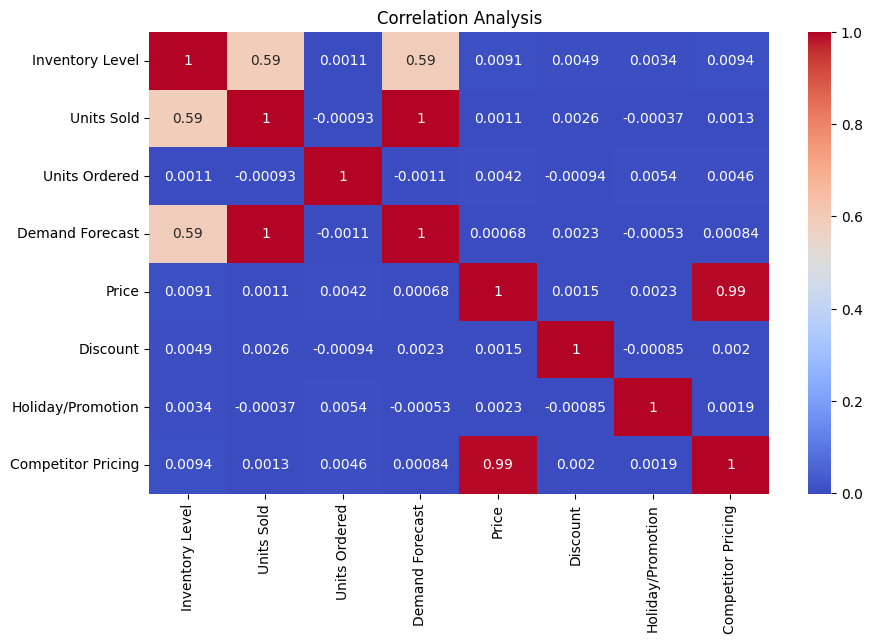

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(10,6))

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Analysis')
plt.show()

In [ ]:
product_data = df[
    (df['Product ID'] == 'P0001') &
    (df['Store ID'] == 'S001')
].copy()

product_data['Date'] = pd.to_datetime(product_data['Date'])

product_data = product_data.sort_values('Date')

print(product_data.head())
print(product_data.shape)

          Date Store ID Product ID     Category Region  Inventory Level  \
0   2022-01-01     S001      P0001    Groceries  North              231   
100 2022-01-02     S001      P0001    Groceries   West              116   
200 2022-01-03     S001      P0001  Electronics   West              154   
300 2022-01-04     S001      P0001    Groceries  South               85   
400 2022-01-05     S001      P0001    Groceries  South              238   

     Units Sold  Units Ordered  Demand Forecast  Price  Discount  \
0           127             55           135.47  33.50        20   
100          81            104            92.94  27.95        10   
200           5            189             5.36  62.70        20   
300          58            193            52.87  77.88        15   
400         147             37           150.27  28.46        20   

    Weather Condition  Holiday/Promotion  Competitor Pricing Seasonality  \
0               Rainy                  0               29.69    

In [ ]:
ts = product_data[['Date', 'Units Sold']].copy()

ts = ts.groupby('Date')['Units Sold'].sum().sort_index()

print(ts.head())
print(ts.tail())

Date
2022-01-01    127
2022-01-02     81
2022-01-03      5
2022-01-04     58
2022-01-05    147
Name: Units Sold, dtype: int64
Date
2023-12-28     67
2023-12-29    168
2023-12-30     30
2023-12-31     26
2024-01-01     40
Name: Units Sold, dtype: int64


In [ ]:
split_index = int(len(ts) * 0.8)

train = ts.iloc[:split_index]
test = ts.iloc[split_index:]

print("Training Records:", len(train))
print("Testing Records:", len(test))
print("Training Period:", train.index.min(), "to", train.index.max())
print("Testing Period:", test.index.min(), "to", test.index.max())

Training Records: 584
Testing Records: 147
Training Period: 2022-01-01 00:00:00 to 2023-08-07 00:00:00
Testing Period: 2023-08-08 00:00:00 to 2024-01-01 00:00:00


In [ ]:
naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index
)

print(naive_forecast.head())

Date
2023-08-08    14
2023-08-09    14
2023-08-10    14
2023-08-11    14
2023-08-12    14
dtype: int64


In [ ]:
moving_average_value = train.tail(7).mean()

moving_average_forecast = pd.Series(
    moving_average_value,
    index=test.index
)

print(moving_average_forecast.head())

Date
2023-08-08    139.571429
2023-08-09    139.571429
2023-08-10    139.571429
2023-08-11    139.571429
2023-08-12    139.571429
dtype: float64


In [ ]:
seasonal_forecast = pd.Series(
    [train.iloc[-7 + (i % 7)] for i in range(len(test))],
    index=test.index
)

print(seasonal_forecast.head())

Date
2023-08-08    109
2023-08-09    154
2023-08-10    435
2023-08-11     55
2023-08-12     23
dtype: int64


In [ ]:
results = pd.DataFrame({
    'Actual': test,
    'Naive': naive_forecast,
    'Moving Average': moving_average_forecast,
    'Seasonal Naive': seasonal_forecast
})

print(results.head(15))

            Actual  Naive  Moving Average  Seasonal Naive
Date                                                     
2023-08-08     335     14      139.571429             109
2023-08-09     455     14      139.571429             154
2023-08-10     176     14      139.571429             435
2023-08-11      90     14      139.571429              55
2023-08-12      46     14      139.571429              23
2023-08-13     145     14      139.571429             187
2023-08-14      72     14      139.571429              14
2023-08-15     289     14      139.571429             109
2023-08-16      50     14      139.571429             154
2023-08-17     225     14      139.571429             435
2023-08-18     293     14      139.571429              55
2023-08-19      39     14      139.571429              23
2023-08-20      31     14      139.571429             187
2023-08-21     115     14      139.571429              14
2023-08-22     143     14      139.571429             109


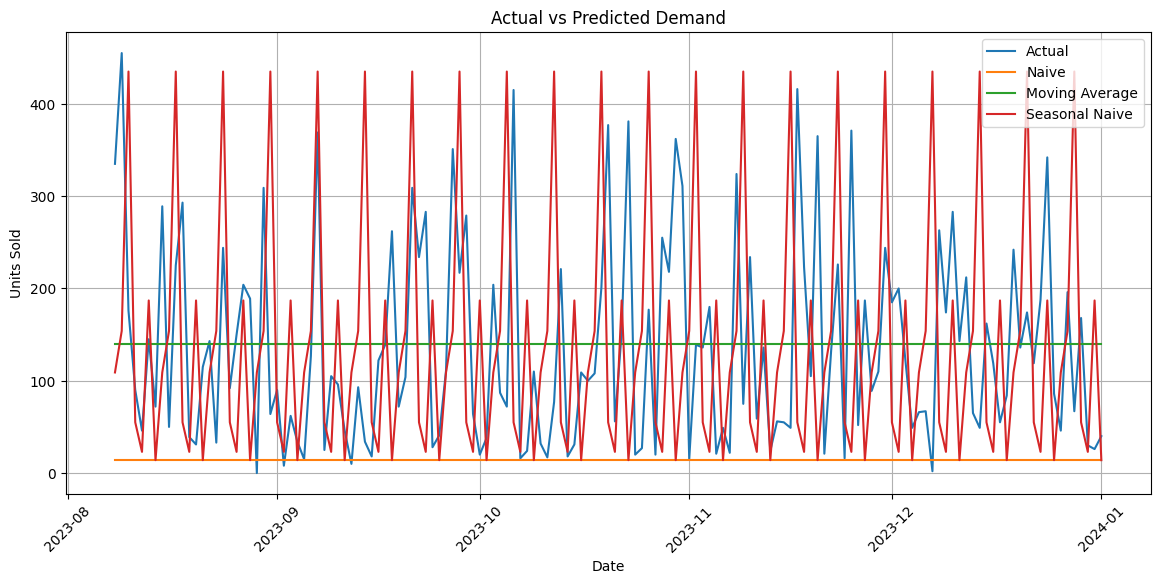

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(results.index, results['Actual'], label='Actual')
plt.plot(results.index, results['Naive'], label='Naive')
plt.plot(results.index, results['Moving Average'], label='Moving Average')
plt.plot(results.index, results['Seasonal Naive'], label='Seasonal Naive')

plt.title('Actual vs Predicted Demand')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (np.abs(actual - predicted).sum() / np.abs(actual).sum()) * 100 if np.abs(actual).sum() != 0 else np.nan

    return mae, rmse, wape

models = {
    'Naive': naive_forecast,
    'Moving Average': moving_average_forecast,
    'Seasonal Naive': seasonal_forecast
}

evaluation = []

for name, prediction in models.items():
    mae, rmse, wape = evaluate_model(test, prediction)
    evaluation.append([name, mae, rmse, wape])

evaluation_df = pd.DataFrame(
    evaluation,
    columns=['Model', 'MAE', 'RMSE', 'WAPE']
)

print(evaluation_df)

            Model         MAE        RMSE       WAPE
0           Naive  123.115646  164.463506  90.111532
1  Moving Average   91.128280  109.634950  66.699149
2  Seasonal Naive  135.190476  172.647551  98.949412


In [ ]:
best_model = evaluation_df.loc[evaluation_df['WAPE'].idxmin()]

print("Best Baseline Model:", best_model['Model'])
print("WAPE:", best_model['WAPE'])

Best Baseline Model: Moving Average
WAPE: 66.69914928727914


In [ ]:
evaluation_df = evaluation_df.sort_values(by='MAE')

print(evaluation_df)

            Model         MAE        RMSE       WAPE
1  Moving Average   91.128280  109.634950  66.699149
0           Naive  123.115646  164.463506  90.111532
2  Seasonal Naive  135.190476  172.647551  98.949412


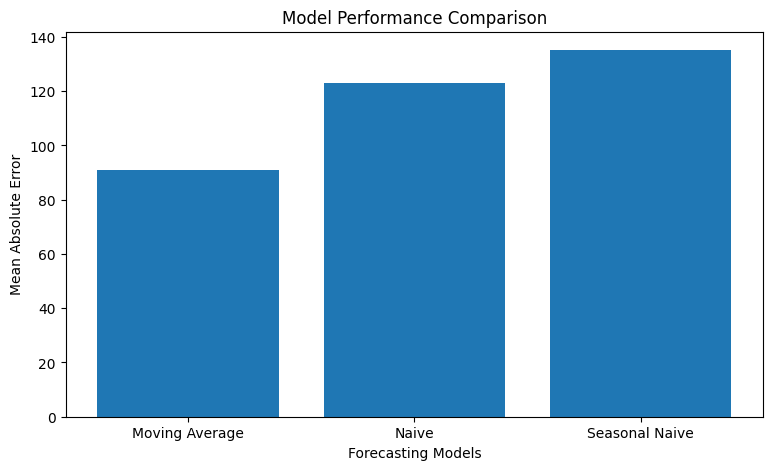

In [ ]:
plt.figure(figsize=(9,5))

plt.bar(evaluation_df['Model'], evaluation_df['MAE'])

plt.title('Model Performance Comparison')
plt.xlabel('Forecasting Models')
plt.ylabel('Mean Absolute Error')

plt.show()

In [ ]:
results['Naive Error'] = results['Actual'] - results['Naive']

results['Moving Average Error'] = results['Actual'] - results['Moving Average']

results['Seasonal Naive Error'] = results['Actual'] - results['Seasonal Naive']

print(results.head(15))

            Actual  Naive  Moving Average  Seasonal Naive  Naive Error  \
Date                                                                     
2023-08-08     335     14      139.571429             109          321   
2023-08-09     455     14      139.571429             154          441   
2023-08-10     176     14      139.571429             435          162   
2023-08-11      90     14      139.571429              55           76   
2023-08-12      46     14      139.571429              23           32   
2023-08-13     145     14      139.571429             187          131   
2023-08-14      72     14      139.571429              14           58   
2023-08-15     289     14      139.571429             109          275   
2023-08-16      50     14      139.571429             154           36   
2023-08-17     225     14      139.571429             435          211   
2023-08-18     293     14      139.571429              55          279   
2023-08-19      39     14      139.571

In [ ]:
results.to_csv('baseline_forecasting_results.csv')

evaluation_df.to_csv('model_evaluation_results.csv', index=False)

print("Forecasting results saved successfully")

Forecasting results saved successfully


In [ ]:
best_model = evaluation_df.loc[evaluation_df['WAPE'].idxmin()]

print("Week 3 Forecasting Summary")
print("--------------------------")
print("Product ID:", 'P0001')
print("Store ID:", 'S001')
print("Best Model:", best_model['Model'])
print("MAE:", best_model['MAE'])
print("RMSE:", best_model['RMSE'])
print("WAPE:", best_model['WAPE'])

Week 3 Forecasting Summary
--------------------------
Product ID: P0001
Store ID: S001
Best Model: Moving Average
MAE: 91.12827988338191
RMSE: 109.63494952538812
WAPE: 66.69914928727914


In [ ]:
!pip install prophet

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
prophet_df = product_data[['Date', 'Units Sold']].copy()

prophet_df = prophet_df.groupby('Date')['Units Sold'].sum().reset_index()

prophet_df.columns = ['ds', 'y']

prophet_df = prophet_df.sort_values('ds')

print(prophet_df.head())

          ds    y
0 2022-01-01  127
1 2022-01-02   81
2 2022-01-03    5
3 2022-01-04   58
4 2022-01-05  147


In [ ]:
split_index = int(len(prophet_df) * 0.8)

train_prophet = prophet_df.iloc[:split_index].copy()
test_prophet = prophet_df.iloc[split_index:].copy()

print("Training records:", len(train_prophet))
print("Testing records:", len(test_prophet))

Training records: 584
Testing records: 147


In [ ]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model.fit(train_prophet)

In [ ]:
future = test_prophet[['ds']].copy()

forecast = model.predict(future)

print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

          ds        yhat  yhat_lower  yhat_upper
0 2023-08-08  160.743419   26.598006  293.817523
1 2023-08-09  166.161165   25.194865  301.740201
2 2023-08-10  164.794870   34.980930  299.219345
3 2023-08-11  151.193921   25.307435  297.255072
4 2023-08-12  150.754752   17.430194  289.607981


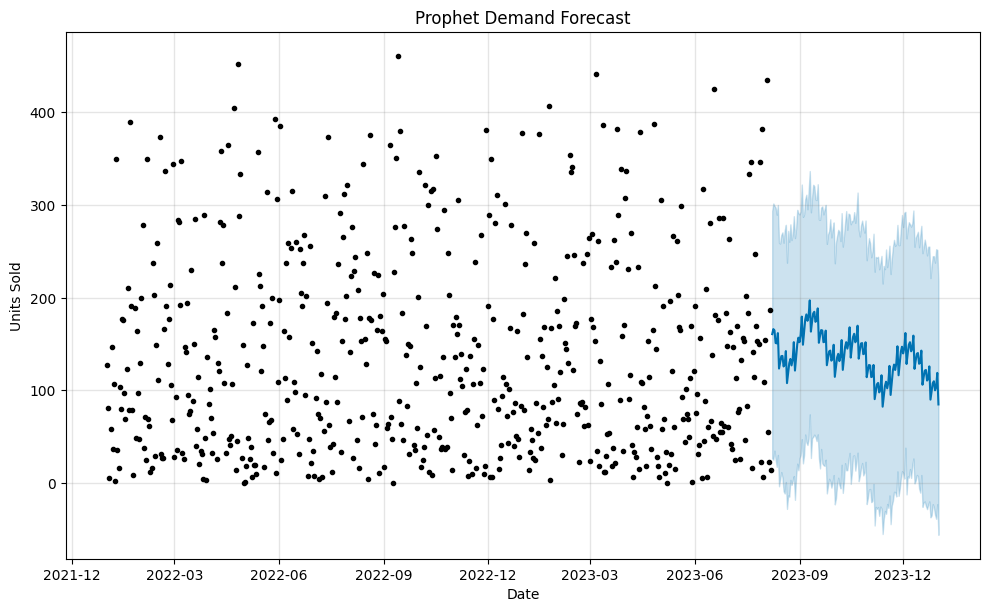

In [ ]:
model.plot(forecast)

plt.title('Prophet Demand Forecast')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.show()

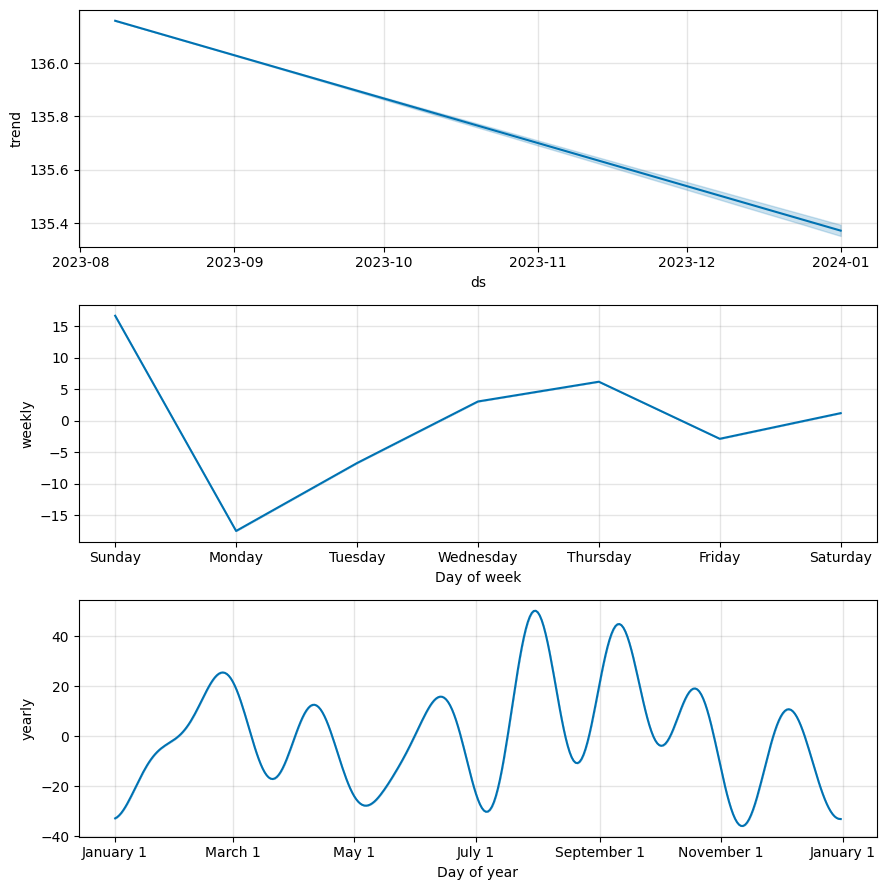

In [ ]:
model.plot_components(forecast)

plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = test_prophet['y'].values
predicted = forecast['yhat'].values

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(mean_squared_error(actual, predicted))

wape = (
    np.abs(actual - predicted).sum() / np.abs(actual).sum()
) * 100 if np.abs(actual).sum() != 0 else np.nan

print("Prophet MAE:", mae)
print("Prophet RMSE:", rmse)
print("Prophet WAPE:", wape)

Prophet MAE: 93.50230567371189
Prophet RMSE: 112.7149023023444
Prophet WAPE: 68.43676027701477


In [ ]:
prophet_comparison = pd.DataFrame({
    'Model': ['Prophet'],
    'MAE': [mae],
    'RMSE': [rmse],
    'WAPE': [wape]
})

final_comparison = pd.concat(
    [evaluation_df, prophet_comparison],
    ignore_index=True
)

print(final_comparison)

            Model         MAE        RMSE       WAPE
0  Moving Average   91.128280  109.634950  66.699149
1           Naive  123.115646  164.463506  90.111532
2  Seasonal Naive  135.190476  172.647551  98.949412
3         Prophet   93.502306  112.714902  68.436760


In [ ]:
final_comparison = final_comparison.sort_values(by='WAPE')

print(final_comparison)

            Model         MAE        RMSE       WAPE
0  Moving Average   91.128280  109.634950  66.699149
3         Prophet   93.502306  112.714902  68.436760
1           Naive  123.115646  164.463506  90.111532
2  Seasonal Naive  135.190476  172.647551  98.949412


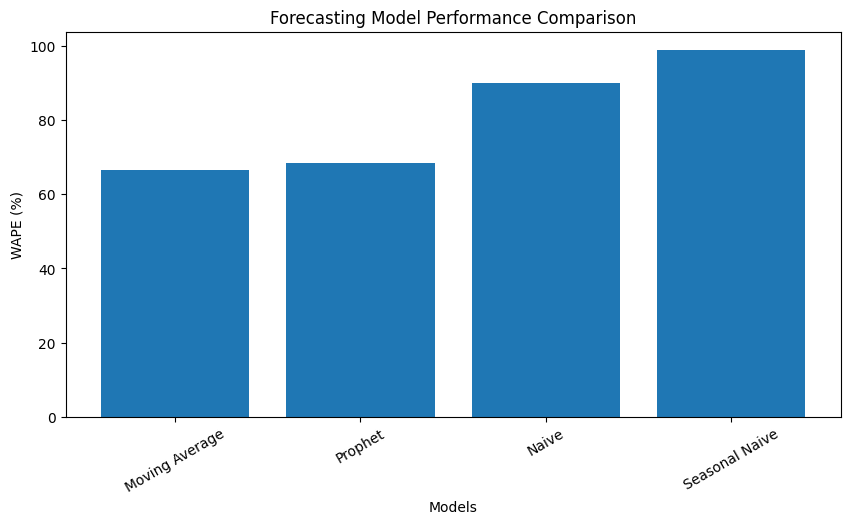

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(final_comparison['Model'], final_comparison['WAPE'])

plt.title('Forecasting Model Performance Comparison')
plt.xlabel('Models')
plt.ylabel('WAPE (%)')
plt.xticks(rotation=30)
plt.show()

In [ ]:
prophet_results = pd.DataFrame({
    'Date': test_prophet['ds'].values,
    'Actual Demand': test_prophet['y'].values,
    'Predicted Demand': forecast['yhat'].values
})

print(prophet_results.head(10))

        Date  Actual Demand  Predicted Demand
0 2023-08-08            335        160.743419
1 2023-08-09            455        166.161165
2 2023-08-10            176        164.794870
3 2023-08-11             90        151.193921
4 2023-08-12             46        150.754752
5 2023-08-13            145        161.827453
6 2023-08-14             72        123.593530
7 2023-08-15            289        130.568560
8 2023-08-16             50        136.954613
9 2023-08-17            225        137.196851


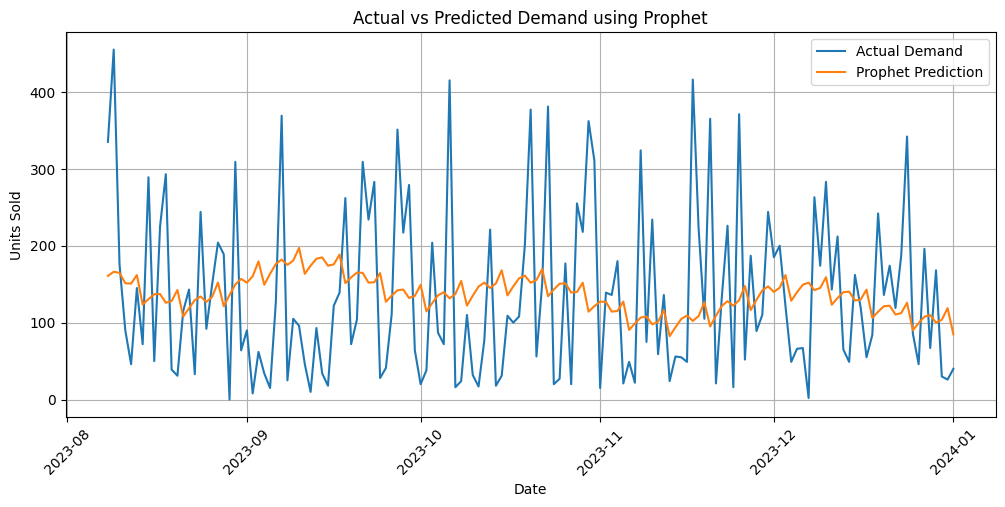

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(prophet_results['Date'], prophet_results['Actual Demand'], label='Actual Demand')
plt.plot(prophet_results['Date'], prophet_results['Predicted Demand'], label='Prophet Prediction')

plt.title('Actual vs Predicted Demand using Prophet')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [ ]:
prophet_results.to_csv('prophet_forecasting_results.csv', index=False)

final_comparison.to_csv('forecasting_model_comparison.csv', index=False)

print("Week 4 results saved successfully")

Week 4 results saved successfully


In [ ]:
!pip install xgboost

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
xgb_df = product_data[['Date', 'Units Sold']].copy()

xgb_df['Date'] = pd.to_datetime(xgb_df['Date'])

xgb_df = xgb_df.groupby('Date')['Units Sold'].sum().sort_index()

xgb_df = xgb_df.asfreq('D')

print(xgb_df.head())
print(xgb_df.shape)
print(xgb_df.isnull().sum())

Date
2022-01-01    127
2022-01-02     81
2022-01-03      5
2022-01-04     58
2022-01-05    147
Freq: D, Name: Units Sold, dtype: int64
(731,)
0


In [ ]:
xgb_data = xgb_df.to_frame()

xgb_data['Day'] = xgb_data.index.day
xgb_data['Month'] = xgb_data.index.month
xgb_data['DayOfWeek'] = xgb_data.index.dayofweek
xgb_data['Year'] = xgb_data.index.year

print(xgb_data.head())

            Units Sold  Day  Month  DayOfWeek  Year
Date                                               
2022-01-01         127    1      1          5  2022
2022-01-02          81    2      1          6  2022
2022-01-03           5    3      1          0  2022
2022-01-04          58    4      1          1  2022
2022-01-05         147    5      1          2  2022


In [ ]:
xgb_data['Lag_1'] = xgb_data['Units Sold'].shift(1)

xgb_data['Lag_7'] = xgb_data['Units Sold'].shift(7)

xgb_data['Lag_14'] = xgb_data['Units Sold'].shift(14)

xgb_data['Rolling_Mean_7'] = xgb_data['Units Sold'].shift(1).rolling(7).mean()

xgb_data = xgb_data.dropna()

print(xgb_data.head())

            Units Sold  Day  Month  DayOfWeek  Year  Lag_1  Lag_7  Lag_14  \
Date                                                                        
2022-01-15         176   15      1          5  2022  177.0    2.0   127.0   
2022-01-16          97   16      1          6  2022  176.0  350.0    81.0   
2022-01-17          69   17      1          0  2022   97.0   36.0     5.0   
2022-01-18         123   18      1          1  2022   69.0   16.0    58.0   
2022-01-19         211   19      1          2  2022  123.0  104.0   147.0   

            Rolling_Mean_7  
Date                        
2022-01-15      109.285714  
2022-01-16      134.142857  
2022-01-17       98.000000  
2022-01-18      102.714286  
2022-01-19      118.000000  


In [ ]:
X = xgb_data.drop('Units Sold', axis=1)

y = xgb_data['Units Sold']

print(X.head())
print(y.head())

            Day  Month  DayOfWeek  Year
Date                                   
2022-01-01    1      1          5  2022
2022-01-02    2      1          6  2022
2022-01-03    3      1          0  2022
2022-01-04    4      1          1  2022
2022-01-05    5      1          2  2022
Date
2022-01-01    127
2022-01-02     81
2022-01-03      5
2022-01-04     58
2022-01-05    147
Freq: D, Name: Units Sold, dtype: int64


In [ ]:
# Reconstruct xgb_df from product_data
xgb_df = product_data[['Date', 'Units Sold']].copy()
xgb_df['Date'] = pd.to_datetime(xgb_df['Date'])
xgb_df = xgb_df.groupby('Date')['Units Sold'].sum().sort_index()
xgb_df = xgb_df.asfreq('D')

# Reconstruct xgb_data with its features to ensure the variables exist
xgb_data = xgb_df.to_frame()
xgb_data['Day'] = xgb_data.index.day
xgb_data['Month'] = xgb_data.index.month
xgb_data['DayOfWeek'] = xgb_data.index.dayofweek
xgb_data['Year'] = xgb_data.index.year

# Add lag and rolling mean features
xgb_data['Lag_1'] = xgb_data['Units Sold'].shift(1)
xgb_data['Lag_7'] = xgb_data['Units Sold'].shift(7)
xgb_data['Lag_14'] = xgb_data['Units Sold'].shift(14)
xgb_data['Rolling_Mean_7'] = xgb_data['Units Sold'].shift(1).rolling(7).mean()

# Drop NaN values introduced by shifting
xgb_data = xgb_data.dropna()

# Separate features and target
X = xgb_data.drop('Units Sold', axis=1)
y = xgb_data['Units Sold']

# Train-test split (80/20)
split_index = int(len(xgb_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 573
Testing records: 144


In [ ]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    objective='reg:squarederror'
)

xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
xgb_predictions = xgb_model.predict(X_test)

print(xgb_predictions[:10])

[214.67062  154.11087  119.24439   89.075516 138.37114  151.57765
 123.11904  129.94499  128.46596  158.99382 ]


In [ ]:
xgb_results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': xgb_predictions
})

print(xgb_results.head(15))

            Actual   Predicted
Date                          
2023-08-11      90  214.670624
2023-08-12      46  154.110870
2023-08-13     145  119.244392
2023-08-14      72   89.075516
2023-08-15     289  138.371140
2023-08-16      50  151.577652
2023-08-17     225  123.119041
2023-08-18     293  129.944992
2023-08-19      39  128.465958
2023-08-20      31  158.993820
2023-08-21     115  123.392799
2023-08-22     143  157.385864
2023-08-23      33  126.563721
2023-08-24     244  147.368027
2023-08-25      92  120.328186


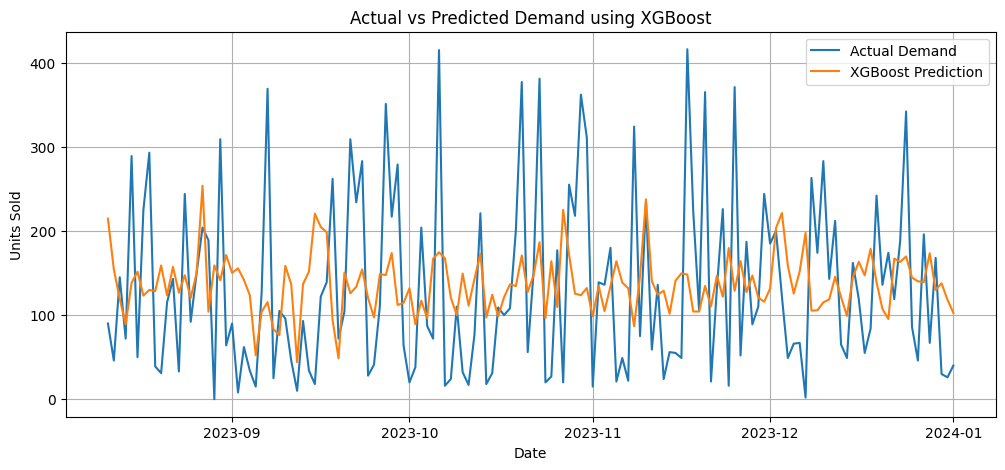

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(xgb_results.index, xgb_results['Actual'], label='Actual Demand')

plt.plot(xgb_results.index, xgb_results['Predicted'], label='XGBoost Prediction')

plt.title('Actual vs Predicted Demand using XGBoost')
plt.xlabel('Date')
plt.ylabel('Units Sold')

plt.legend()
plt.grid()
plt.show()

In [ ]:
xgb_mae = mean_absolute_error(y_test, xgb_predictions)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))

xgb_wape = (
    np.abs(y_test - xgb_predictions).sum() / np.abs(y_test).sum()
) * 100 if np.abs(y_test).sum() != 0 else np.nan

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost WAPE:", xgb_wape)

XGBoost MAE: 90.22702026367188
XGBoost RMSE: 109.0082870272944
XGBoost WAPE: 67.96051322297704


In [ ]:
xgb_comparison = pd.DataFrame({
    'Model': ['XGBoost'],
    'MAE': [xgb_mae],
    'RMSE': [xgb_rmse],
    'WAPE': [xgb_wape]
})

all_models_comparison = pd.concat(
    [final_comparison, xgb_comparison],
    ignore_index=True
)

print(all_models_comparison.sort_values('WAPE'))

            Model         MAE        RMSE       WAPE
0  Moving Average   91.128280  109.634950  66.699149
4         XGBoost   90.227020  109.008287  67.960513
1         Prophet   93.502306  112.714902  68.436760
2           Naive  123.115646  164.463506  90.111532
3  Seasonal Naive  135.190476  172.647551  98.949412


In [ ]:
xgb_results.to_csv('xgboost_forecasting_results.csv')

all_models_comparison.to_csv(
    'all_models_comparison.csv',
    index=False
)

print("Week 5 results saved successfully")

Week 5 results saved successfully


In [ ]:
print(all_models_comparison)

            Model         MAE        RMSE       WAPE
0  Moving Average   91.128280  109.634950  66.699149
1         Prophet   93.502306  112.714902  68.436760
2           Naive  123.115646  164.463506  90.111532
3  Seasonal Naive  135.190476  172.647551  98.949412
4         XGBoost   90.227020  109.008287  67.960513


In [ ]:
comparison_data = pd.DataFrame({
    'Actual': test,
    'Naive': naive_forecast,
    'Moving Average': moving_average_forecast,
    'Seasonal Naive': seasonal_forecast
})

prophet_series = pd.Series(
    forecast['yhat'].values,
    index=pd.to_datetime(forecast['ds'])
)

xgb_series = pd.Series(
    xgb_predictions,
    index=pd.to_datetime(y_test.index)
)

comparison_data['Prophet'] = prophet_series
comparison_data['XGBoost'] = xgb_series

comparison_data = comparison_data.dropna()

print(comparison_data.head())
print("Common test records:", len(comparison_data))

            Actual  Naive  Moving Average  Seasonal Naive     Prophet  \
Date                                                                    
2023-08-11      90     14      139.571429              55  151.193921   
2023-08-12      46     14      139.571429              23  150.754752   
2023-08-13     145     14      139.571429             187  161.827453   
2023-08-14      72     14      139.571429              14  123.593530   
2023-08-15     289     14      139.571429             109  130.568560   

               XGBoost  
Date                    
2023-08-11  214.670624  
2023-08-12  154.110870  
2023-08-13  119.244392  
2023-08-14   89.075516  
2023-08-15  138.371140  
Common test records: 144


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model_names = [
    'Naive',
    'Moving Average',
    'Seasonal Naive',
    'Prophet',
    'XGBoost'
]

comparison_results = []

for name in model_names:
    actual = comparison_data['Actual']
    predicted = comparison_data[name]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    wape = (
        np.abs(actual - predicted).sum() /
        np.abs(actual).sum()
    ) * 100 if np.abs(actual).sum() != 0 else np.nan

    comparison_results.append([name, mae, rmse, wape])

week6_results = pd.DataFrame(
    comparison_results,
    columns=['Model', 'MAE', 'RMSE', 'WAPE']
)

print(week6_results)

            Model         MAE        RMSE       WAPE
0           Naive  119.263889  159.258830  89.831572
1  Moving Average   89.226190  106.324298  67.206671
2  Seasonal Naive  132.548611  170.230583  99.837849
3         Prophet   92.156517  110.355003  69.413842
4         XGBoost   90.227020  109.008287  67.960513


In [ ]:
best_model = week6_results.loc[
    week6_results['WAPE'].idxmin()
]

print("Best Performing Model:", best_model['Model'])
print("MAE:", best_model['MAE'])
print("RMSE:", best_model['RMSE'])
print("WAPE:", best_model['WAPE'])

Best Performing Model: Moving Average
MAE: 89.22619047619048
RMSE: 106.32429775228712
WAPE: 67.2066713493641


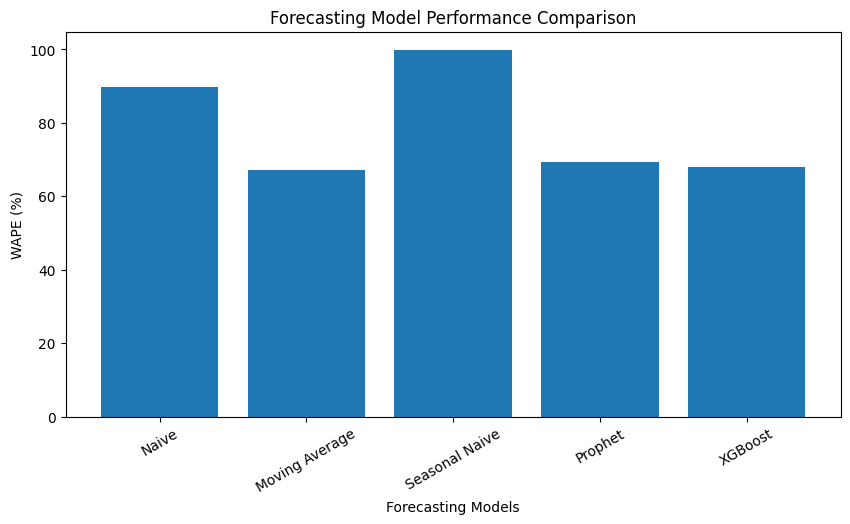

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(week6_results['Model'], week6_results['WAPE'])

plt.title('Forecasting Model Performance Comparison')
plt.xlabel('Forecasting Models')
plt.ylabel('WAPE (%)')
plt.xticks(rotation=30)
plt.show()

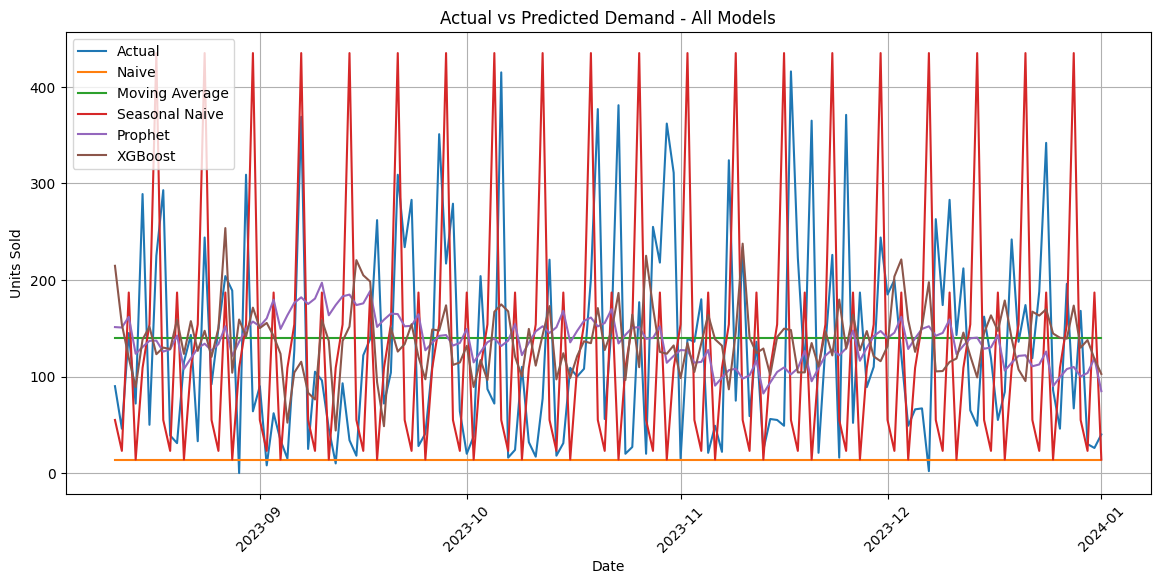

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(comparison_data.index, comparison_data['Actual'], label='Actual')

for name in model_names:
    plt.plot(comparison_data.index, comparison_data[name], label=name)

plt.title('Actual vs Predicted Demand - All Models')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [ ]:
results.to_csv('model_comparison.csv', index=False)

comparison_data.to_csv('forecast_comparison.csv')

print(" results saved successfully")

 results saved successfully


In [ ]:
import os

print(os.listdir())

['.config', 'retail_store_inventory.csv', 'forecasting_model_comparison.csv', 'baseline_forecasting_results.csv', 'xgboost_forecasting_results.csv', 'model_comparison.csv', 'forecast_comparison.csv', 'prophet_forecasting_results.csv', 'all_models_comparison.csv', 'model_evaluation_results.csv', 'sample_data']
